In [20]:
from langgraph.graph import StateGraph,START,END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
load_dotenv()
from typing import TypedDict,Annotated
from pydantic import BaseModel,Field
import operator
import os
import json

In [21]:
print("API key loaded:", bool(os.getenv("OLLAMA_API_KEY")))

API key loaded: True


In [22]:
llm = ChatOpenAI(
    model="gpt-oss:20b",
    base_url="https://ollama.com/v1",
    api_key=os.getenv("OLLAMA_API_KEY"),
    temperature=0
)


In [23]:
class EvaluationSchema(BaseModel):

    feedback: str = Field(description='Detailed feedback for the essay')
    score: int = Field(description='Score out of 10', ge=0, le=10)

In [24]:
structured_model = llm.with_structured_output(
    EvaluationSchema,
    method="json_mode"
)

In [25]:
essay = """Europe in the Age of AI: The Regulatory Superpower

As the world rushes headlong into the era of artificial intelligence, the European Union finds itself playing a unique and complex role. While the United States and China dominate the race to build the largest foundation models and hardware ecosystems, Europe has positioned itself as the global conscience of the AI age. For Europe, the challenge is not simply about technological supremacy, but about ensuring that AI aligns with democratic values, human rights, and environmental sustainability.

Europe's strengths lie in its deep academic traditions and its commitment to ethical frameworks. The continent is home to world-class research hubs, producing some of the leading minds in machine learning. Furthermore, Europe has a distinct advantage in industrial and B2B AI, driven by its manufacturing powerhouses in Germany, France, and Scandinavia. However, Europe’s most defining characteristic in this era is its regulatory muscle. With the passage of the AI Act, the EU has created the world’s first comprehensive legal framework for artificial intelligence, categorizing systems by risk and demanding unprecedented transparency from tech companies.

The European vision for AI is heavily focused on public good and sustainability. There is a strong push toward "Green AI," ensuring that the massive energy consumption of data centers aligns with the continent's aggressive climate goals. In healthcare, European nations are leveraging AI to advance precision medicine and streamline public health systems, while fiercely protecting patient data. Additionally, significant investments are being made to develop open-source, multilingual AI models that preserve Europe's rich linguistic diversity and reduce reliance on Silicon Valley.

Despite these noble ambitions, Europe faces substantial hurdles. The continent suffers from a severe lack of hyperscale tech companies and domestic cloud infrastructure, leaving it heavily dependent on foreign technology. This "compute deficit" is compounded by a fragmented venture capital market, which often struggles to commercialize academic breakthroughs. Consequently, Europe frequently experiences a brain drain, as its brightest AI researchers are lured away by the massive salaries and computing resources offered by American and Chinese tech giants.

The central tension for Europe is whether its regulatory approach will foster "trustworthy AI" or stifle homegrown innovation. Critics argue that stringent compliance burdens will price European startups out of the market, relegating the continent to being a consumer of foreign AI rather than a creator. Proponents, however, believe that by setting global ethical standards—the "Brussels Effect"—Europe will ultimately attract users and enterprises that demand secure, unbiased, and privacy-respecting technologies.

To succeed, Europe must balance its protective instincts with aggressive investment in digital infrastructure and innovation. It needs to foster a unified digital single market that allows startups to scale across borders effortlessly, while also forging strategic alliances to secure supply chains for critical hardware like semiconductors.

In conclusion, Europe in the age of AI represents a profound geopolitical experiment. It is testing whether a society can successfully govern exponential technology without sacrificing economic competitiveness. If Europe succeeds, it will provide a desperately needed global blueprint for human-centric AI; if it fails, it risks becoming an over-regulated museum in a world driven by algorithmic innovation."""

In [26]:
response = llm.invoke(
    f"""
    Evaluate this essay's language quality.

    Return ONLY a valid JSON object with:
    - feedback: a string
    - score: an integer between 0 and 10

    Do not include Markdown code fences.

    Essay:
    {essay}
    """
)

result=json.loads(response.content)

In [27]:
print(result['feedback'])
print(result['score'])

The essay demonstrates strong command of language, with clear structure, varied vocabulary, and persuasive argumentation. Sentences are generally well-constructed and the tone is appropriately formal for an analytical piece. Minor issues include occasional repetition, slightly awkward phrasing in a few places, and a small factual slip (referring to Scandinavia as a single country). Overall, the language quality is high and effectively supports the essay’s points.
9


In [28]:
class EssayState(TypedDict):

    essay: str
    language_feedback: str
    analysis_feedback: str
    clarity_feedback: str
    overall_feedback: str
    individual_scores: Annotated[list[int], operator.add]
    avg_score: float

In [29]:
def evaluate_language(essay: str) -> EssayState:
    prompt=f'Evaluate this essay\'s language quality.\n\nReturn ONLY a valid JSON object with:\n- feedback: a string\n- score: an integer between 0 and 10\n\nDo not include Markdown code fences.\n\nEssay:\n{essay}'
    llm_response = llm.invoke(prompt)
    result = json.loads(llm_response.content)
    return {
        'language_feedback': result['feedback'],
        'individual_scores': [result['score']]
    }

In [30]:
def evaluate_analysis(essay: str) -> EssayState:
    prompt=f'Evaluate this essay\'s analysis quality.\n\nReturn ONLY a valid JSON object with:\n- feedback: a string\n- score: an integer between 0 and 10\n\nDo not include Markdown code fences.\n\nEssay:\n{essay}'
    llm_response = llm.invoke(prompt)
    result = json.loads(llm_response.content)
    return {
        'analysis_feedback': result['feedback'],
        'individual_scores': [result['score']]
    }

In [31]:
def evaluate_thought_clarity(essay: str) -> EssayState:
    prompt=f'Evaluate this essay\'s thought clarity.\n\nReturn ONLY a valid JSON object with:\n- feedback: a string\n- score: an integer between 0 and 10\n\nDo not include Markdown code fences.\n\nEssay:\n{essay}'
    llm_response = llm.invoke(prompt)
    result = json.loads(llm_response.content)
    return {
        'clarity_feedback': result['feedback'],
        'individual_scores': [result['score']]
    }

In [41]:
def final_evaluation(essay_state: EssayState) -> EssayState:
    avg_score = sum(essay_state['individual_scores']) / len(essay_state['individual_scores'])
    overall_feedback = f"Overall feedback:\nLanguage: {essay_state['language_feedback']}\nAnalysis: {essay_state['analysis_feedback']}\nClarity: {essay_state['clarity_feedback']}\nAverage Score: {avg_score:.2f}"
    return {
        'essay': essay_state['essay'],
        'language_feedback': essay_state['language_feedback'],
        'analysis_feedback': essay_state['analysis_feedback'],
        'clarity_feedback': essay_state['clarity_feedback'],
        'overall_feedback': overall_feedback,
        'individual_scores': essay_state['individual_scores'],
        'avg_score': avg_score
    }

In [42]:
graph = StateGraph(EssayState)

graph.add_node('evaluate_language', evaluate_language)
graph.add_node('evaluate_analysis', evaluate_analysis)
graph.add_node('evaluate_thought_clarity', evaluate_thought_clarity)
graph.add_node('final_evaluation', final_evaluation)

graph.add_edge(START, 'evaluate_language')
graph.add_edge(START, 'evaluate_analysis')
graph.add_edge(START, 'evaluate_thought_clarity')

graph.add_edge('evaluate_language', 'final_evaluation')
graph.add_edge('evaluate_analysis', 'final_evaluation')
graph.add_edge('evaluate_thought_clarity', 'final_evaluation')

graph.add_edge('final_evaluation', END)

workflow=graph.compile()

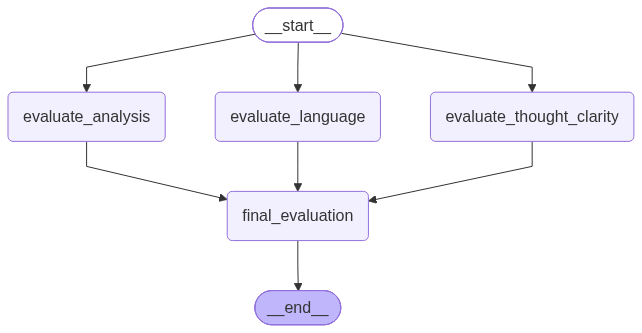

In [43]:
workflow

In [44]:
essay2="""Essay: The Role of Annotated and Reducers in LangGraph
In Python, Annotated is a feature provided by the typing module that allows us to attach additional information, called metadata, to a type. It does not perform any operation by itself. In LangGraph, Annotated is commonly used to associate a reducer function with a state field.

A reducer is a function that determines how new values should be combined with existing values in the graph's state. For example, when a node generates new data, LangGraph needs to know whether to replace the existing value or combine it with the new value. A reducer defines this behavior.

Consider the following example:
from typing import Annotatedfrom typing_extensions import TypedDictimport operatorclass State(TypedDict):    numbers: Annotated[list[int], operator.add]



In this example, list[int] specifies that the numbers field contains a list of integers. The Annotated type attaches operator.add as metadata to this field. The operator.add function acts as the reducer when LangGraph processes state updates.

Suppose the existing state contains [1, 2], and a node returns [3, 4]. The reducer combines these lists, producing [1, 2, 3, 4]. Without a reducer, LangGraph normally replaces the existing value of a state field with the new value.

It is important to understand that Annotated and reducers are different concepts. Annotated provides a way to associate metadata with a type, whereas the reducer is the function that defines how values are combined. LangGraph interprets this metadata and applies the reducer during state updates. This approach works with state schemas defined using TypedDict and can also be used with Pydantic-based state schemas.

In conclusion, Annotated is not itself a reducer. It is a Python typing feature that allows LangGraph to associate a reducer function with a state field. Reducers are useful for managing state updates, especially when multiple nodes contribute information to the same field, such as a list of messages or collected research results."""

In [45]:
initial_state = {
    'essay': essay2
}

In [46]:
result=workflow.invoke(initial_state)
result

{'essay': "Essay: The Role of Annotated and Reducers in LangGraph\nIn Python, Annotated is a feature provided by the typing module that allows us to attach additional information, called metadata, to a type. It does not perform any operation by itself. In LangGraph, Annotated is commonly used to associate a reducer function with a state field.\n\nA reducer is a function that determines how new values should be combined with existing values in the graph's state. For example, when a node generates new data, LangGraph needs to know whether to replace the existing value or combine it with the new value. A reducer defines this behavior.\n\nConsider the following example:\nfrom typing import Annotatedfrom typing_extensions import TypedDictimport operatorclass State(TypedDict):    numbers: Annotated[list[int], operator.add]\n\n\n\nIn this example, list[int] specifies that the numbers field contains a list of integers. The Annotated type attaches operator.add as metadata to this field. The ope